[INFO] Total amostras (['v1', 'v2', 'v3']): 229
[INFO] Total amostras teste: 229


C:\Users\Douglas\AppData\Local\Temp\ipykernel_24976\1927553915.py:71: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load("C:\\Users\\Douglas\\OneDrive - cefet-rj.br\\D


===== RESULTADOS =====
MSE : 72.5489
MAE : 6.7089 BPM
R²  : -0.0742


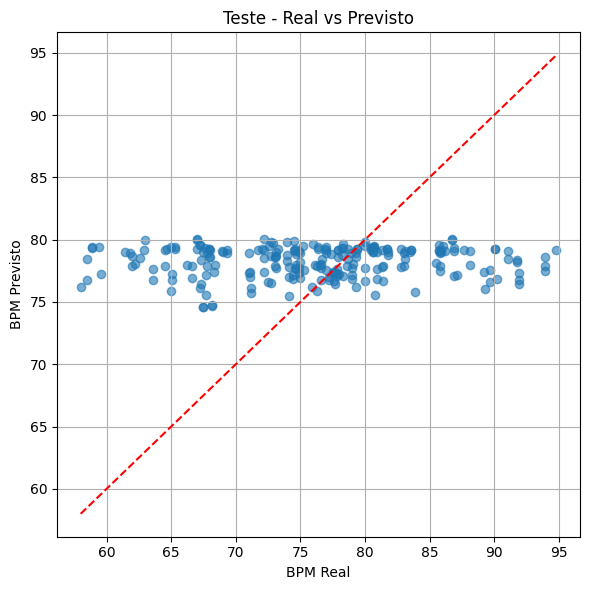

In [7]:
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

from Dataset_VIPHL import IPPGDatasetBase
from Model_CNN import IPPGCNN

# =========================
# CONFIGURAÇÃO
# =========================

test_root = r"C:\Users\Douglas\Documents\VIPL_IPPG_TEST"

# mesmos cenários usados no treino
scenarios = ["v1", "v2", "v3"]

# mesmo sinal usado no treino
signal_type = "ippg1"

# mesmo segmento usado no treino
start_sec = 1
end_sec = 11

# batch
batch_size = 8

# modelo treinado
model_path = "model_v1_ippg3.pth"

# =========================
# CARREGAR MEAN / STD
# =========================

mean_bpm, std_bpm = np.load(
    r"C:\Users\Douglas\OneDrive - cefet-rj.br\Documentos\Material _ faculdade\Projeto IC\Monitoramento_FA_PA\bpm_mean_std.npy"
)

# =========================
# DATASET DE TESTE
# =========================

test_dataset = IPPGDatasetBase(
    root_dir=test_root,
    scenario=scenarios,
    ippg_type=signal_type,
    mean=mean_bpm,
    std=std_bpm,
    start_sec=start_sec,
    end_sec=end_sec
)

print(f"[INFO] Total amostras teste: {len(test_dataset)}")

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

# =========================
# MODELO
# =========================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = IPPGCNN().to(device)

model.load_state_dict(
    torch.load("C:\\Users\\Douglas\\OneDrive - cefet-rj.br\\Documentos\\Material _ faculdade\\Projeto IC\\Monitoramento_FA_PA\\model_v1_ippg3.pth", map_location=device)
)

model.eval()

# =========================
# INFERÊNCIA
# =========================

predictions = []
targets = []

with torch.no_grad():

    for inputs, labels in test_loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model(inputs)

        predictions.extend(outputs.cpu().numpy())
        targets.extend(labels.cpu().numpy())

# converter para numpy
predictions = np.array(predictions).flatten()
targets = np.array(targets).flatten()

# =========================
# DESNORMALIZAÇÃO
# =========================

pred_real = predictions * std_bpm + mean_bpm
targ_real = targets * std_bpm + mean_bpm

# =========================
# MÉTRICAS
# =========================

mse = mean_squared_error(targ_real, pred_real)
mae = mean_absolute_error(targ_real, pred_real)
r2 = r2_score(targ_real, pred_real)

print("\n===== RESULTADOS =====")
print(f"MSE : {mse:.4f}")
print(f"MAE : {mae:.4f} BPM")
print(f"R²  : {r2:.4f}")

# =========================
# PLOT
# =========================

plt.figure(figsize=(6,6))

plt.scatter(
    targ_real,
    pred_real,
    alpha=0.6
)

# linha ideal
plt.plot(
    [targ_real.min(), targ_real.max()],
    [targ_real.min(), targ_real.max()],
    'r--'
)

plt.xlabel("BPM Real")
plt.ylabel("BPM Previsto")
plt.title("Teste - Real vs Previsto")

plt.grid(True)
plt.tight_layout()
plt.show()

In [1]:
import torch

print(torch.cuda.is_available())
print(torch.cuda.device_count())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Sem GPU")

True
1
NVIDIA GeForce RTX 4060
